# v7.5

AutoML Fates_v6.0

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle as pkl
from pathlib import Path
import math

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

import subprocess
from IPython.display import display, HTML, clear_output
import warnings
warnings.simplefilter("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

In [19]:
%reload_ext autoreload
%autoreload 2

from pptoolbox.automl import STRATIFIED_KFOLD
from pptoolbox.automl.optuna_op.tuner import AutoML
from pptoolbox.automl.optuna_op.pipeline_constructor import construct_pipeline_from_params
from pptoolbox.visualization import plot_confusion_matrix

from pptoolbox.automl.utils import cross_group_predict

# import data

In [20]:
data_dir = Path("../data/processed")
version = 'v7'
split = f'{version}.5'
data_folder = data_dir / version / split


train_folder = data_folder / "train"
test_folder = data_folder / "test"

X_train = pd.read_csv(train_folder / "input.csv", index_col=0)
y_train = pd.read_csv(train_folder / "label.csv", index_col=0)
meta_train = pd.read_csv(train_folder / "meta.csv", index_col=0)

assert X_train.index.equals(y_train.index)
assert X_train.index.equals(meta_train.index)

X_test = pd.read_csv(test_folder / "input.csv", index_col=0)
y_test = pd.read_csv(test_folder / "label.csv", index_col=0)
meta_test = pd.read_csv(test_folder / "meta.csv", index_col=0)

# assert X_test.index.equals(y_test.index)
# assert X_test.index.equals(meta_test.index)

print(X_train.shape, y_train.shape, meta_train.shape)
print(X_test.shape, y_test.shape, meta_test.shape)

(1186, 191) (1186, 1) (1186, 6)
(266, 191) (266, 1) (266, 6)


In [21]:
y_train[~y_train.index.duplicated(keep='first')].value_counts(['Type']).sort_index()

Type   
Natural     83
Offnote    124
Name: count, dtype: int64

In [22]:
print(y_train.columns)

Index(['Type'], dtype='object')


In [23]:
params_to_train = ['Type']
params_to_train

['Type']

# Classify

## v7.5

In [24]:
model_version = f"{split}.0"

model_folder = Path("../models/") / version / split / model_version
model_folder.mkdir(parents=True, exist_ok=True)
model_folder

WindowsPath('../models/v7/v7.5/v7.5.0')

In [25]:
pipeline.estimator

Pipeline(steps=[('VIS',
                 FeatureMask(mask=array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  Tru...
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False]))),
                ('SNV', SNV()), ('SG2D', SavitzkyGolay(deriv=2, window=7)),
                ('Scaler', StandardScaler(with_std=False)),
                ('PCA', PCA(n_components=23, random_state=42)),
                ('KNN',
                 KNeighborsClassifier(n_neighbors=11, p=1,
                                      weights='distance'))])

Trainer for Type already exists. Loading...
{'mask': 'VIS', 'preprocessor': 'SNV-SGnD', 'preprocessor__deriv': 2, 'preprocessor__window': 7, 'model': 'KNN', 'model__n_neighbors': 11, 'dimred_step': 'yes', 'dimred_method': 'PCA', 'dimred__n_components': 23}


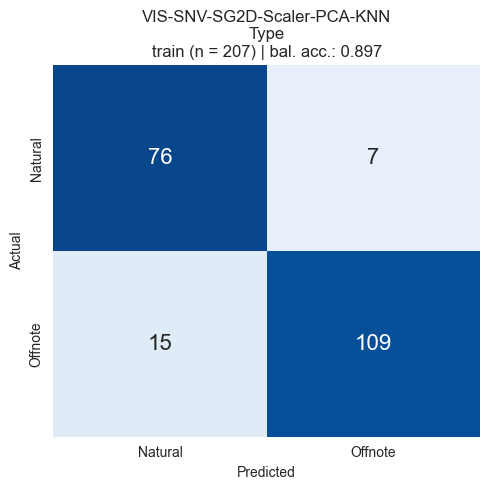

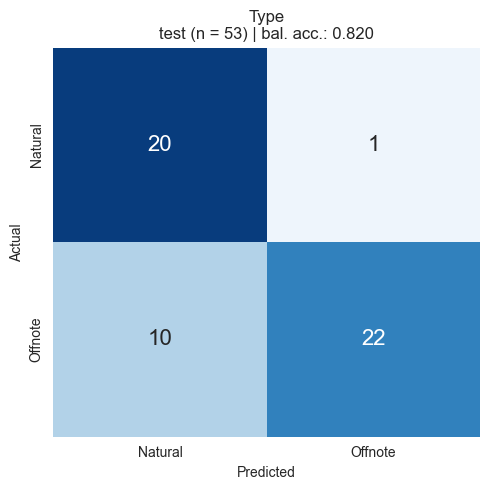

In [ ]:
for i, param in enumerate(params_to_train):
    clear_output(wait=True)

    # if i !=0:
    #     # For testing purposes, only run the first parameter
    #     break

    param_folder = model_folder / f'{param}'
    param_folder.mkdir(parents=True, exist_ok=True)

    STORAGE_URL = f"sqlite:///{param_folder}/model_training.db"

    selected_y_train = y_train[[param]].copy()

    model_name = f'{param}'

    if (param_folder / f"trainer.pkl").exists():
        print(f"Trainer for {param} already exists. Loading...")

        trainer = AutoML.load(param_folder)
        pipeline = trainer.get_pipeline()
        # pipeline_platform = trainer.get_pipeline_platform()

        with open(param_folder / "encoder.pkl", "rb") as f:
            encoder = pkl.load(f)
        selected_y_train_encoded = pd.Series(encoder.transform(selected_y_train).ravel(), index=selected_y_train.index)

    else:
        print(f"Training model for {param}...")

        # Encode labels
        categories = [['Natural','Offnote']]
        encoder = OrdinalEncoder(categories=categories)
        
        selected_y_train_encoded = pd.Series(encoder.fit_transform(selected_y_train).ravel(), index=selected_y_train.index)
        with open(param_folder / "encoder.pkl", "wb") as f:
            pkl.dump(encoder, f)

        # Initialise AutoML model
        trainer = AutoML(
            task_type="classify",
            model_name=model_name,
            metric_names = ["loss"],
            direction = ["minimize",],
            datatype = 'v4'
            # n_startup_trials=10,
            # n_trials=25,
        )

        # # Launch new dashboard
        # dashboard_process = subprocess.Popen(
        #     ["optuna-dashboard", STORAGE_URL, "--port", "8080"]
        # )
        # display(HTML('<a href="http://localhost:8080" target="_blank">Open Optuna Dashboard</a>'))

        trainer.fit(
            X_train,
            selected_y_train_encoded,
            groups=selected_y_train_encoded.index,
            storage=STORAGE_URL,
            repeat = 3
            )
        
        trainer.save(param_folder)

        pipeline = trainer.get_pipeline()

        with open(param_folder / "origin_model_prediction.pkl", "wb") as f:
            pkl.dump(pipeline, f)

    print(trainer.best_params)

    # get cv train
    y_train_pred_encoded = cross_group_predict(
        pipeline.estimator,
        X_train,
        selected_y_train_encoded,
        groups=selected_y_train_encoded.index,
        cv=STRATIFIED_KFOLD
    )

    train_cfm = plot_confusion_matrix(
        y_true = selected_y_train_encoded.groupby(selected_y_train_encoded.index).first().values.reshape(-1, 1),
        y_pred = y_train_pred_encoded.values.reshape(-1, 1),
        encoder = encoder,
        param = "-".join(pipeline.estimator.named_steps.keys()) + "\n" + f'{param}',
        title = "train"
        )
    
    plt.savefig(param_folder / "train_cfm.png")
    plt.show()


    selected_y_test = y_test[[param]]
    selected_y_test_encoded = pd.Series(encoder.transform(selected_y_test).ravel(), index = selected_y_test.index)


    y_test_pred_encoded = pd.DataFrame(pipeline.predict_proba(X_test),index=X_test.index).groupby(X_test.index).median().idxmax(axis=1)
    test_cfm = plot_confusion_matrix(
        y_true = selected_y_test_encoded.groupby(selected_y_test_encoded.index).first().values.reshape(-1, 1),
        y_pred = y_test_pred_encoded.values.reshape(-1, 1),
        encoder = encoder,
        param = param,
        title = "test"
    )

    plt.savefig(param_folder / "test_cfm.png")
    plt.show()
    plt.close()

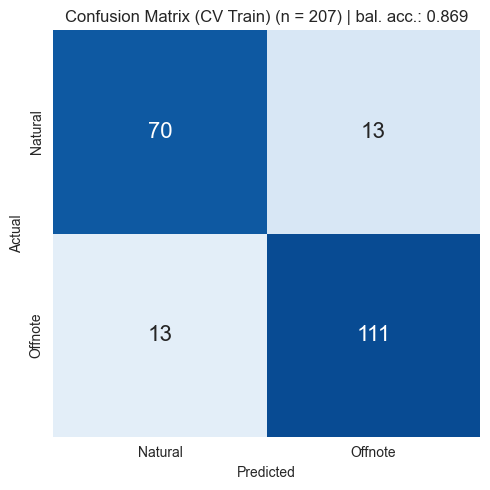

<Figure size 1000x600 with 0 Axes>

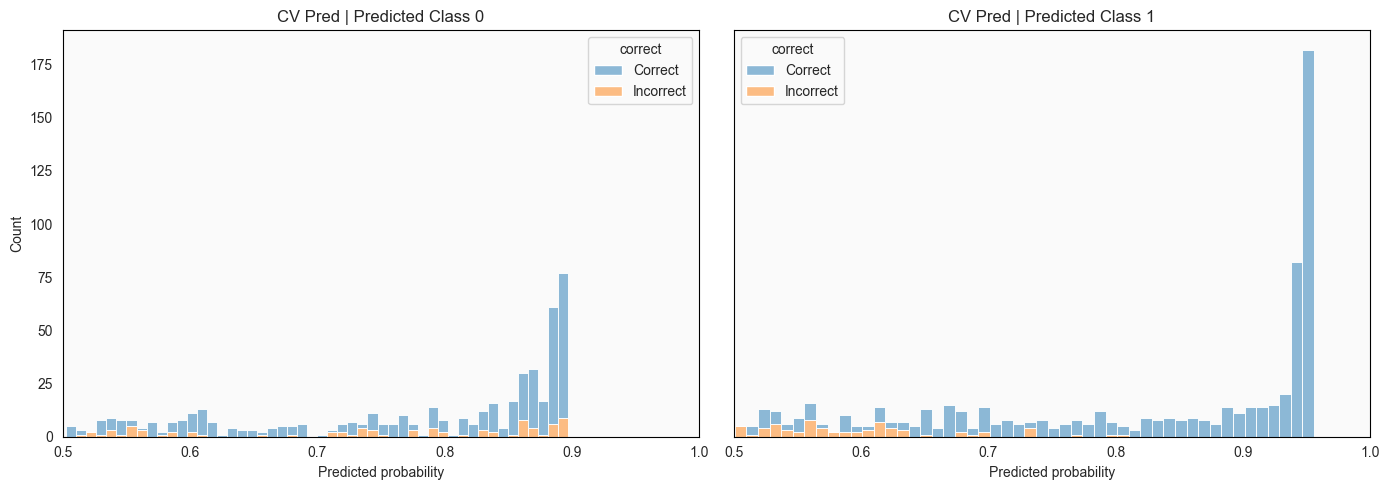

In [28]:
base_pipeline = (
    trainer.best_pipeline.estimator
    if trainer.is_calibrated
    else trainer.best_pipeline
)

preds, proba_matrix = cross_group_predict(
    base_pipeline,
    X=X_train,
    y=selected_y_train_encoded,
    groups=X_train.index,
    cv=STRATIFIED_KFOLD,
    calibrate=trainer.is_calibrated,
    calibration_cv=trainer.calibration_cv,  # optional; defaults to cv
    calibration_method=trainer.calibration_method,
    return_proba_matrix=True,
    spec_level=True
)

pred_lot = proba_matrix.groupby(proba_matrix.index).median().idxmax(axis=1)
selected_y_train_encoded_nodup = selected_y_train_encoded[~selected_y_train_encoded.index.duplicated(keep='first')]
pred_lot = pred_lot.loc[selected_y_train_encoded_nodup.index]

cfm = plot_confusion_matrix(
    y_true=selected_y_train_encoded[~selected_y_train_encoded.index.duplicated(keep='first')],
    y_pred=pred_lot,
    encoder=encoder,
    title="Confusion Matrix (CV Train)"
)

proba_matrix['correct'] = np.where(proba_matrix.index.isin(pred_lot[pred_lot!= selected_y_train_encoded_nodup].index), 'Incorrect', 'Correct')
proba_matrix['correct'] = pd.Categorical(proba_matrix['correct'], categories=['Correct', 'Incorrect'], ordered=True)
fig = plt.figure(figsize=(10, 6))

# plot the distribution of predicted probabilities for the correct and incorrect predictions
proba_cols = [c for c in proba_matrix.columns if c not in ["correct", "pred_class", "idxmax_proba"]]

proba_matrix["pred_class"] = proba_matrix[proba_cols].idxmax(axis=1)
proba_matrix["idxmax_proba"] = proba_matrix[proba_cols].max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, cls in zip(axes, sorted(proba_matrix["pred_class"].unique())):
    sns.histplot(
        data=proba_matrix.loc[proba_matrix["pred_class"] == cls],
        x="idxmax_proba",
        hue="correct",
        bins=50,
        alpha=0.5,
        multiple="stack",
        ax=ax,
    )
    ax.set_title(f"CV Pred | Predicted Class {cls}")
    ax.set_xlabel("Predicted probability")
    ax.set_xlim(0.5, 1.0)  # appropriate for binary classification

plt.tight_layout()

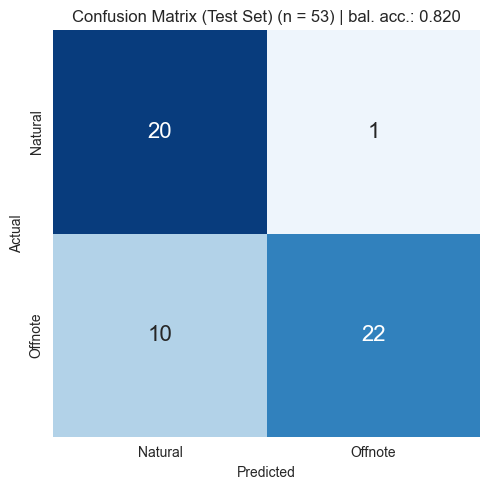

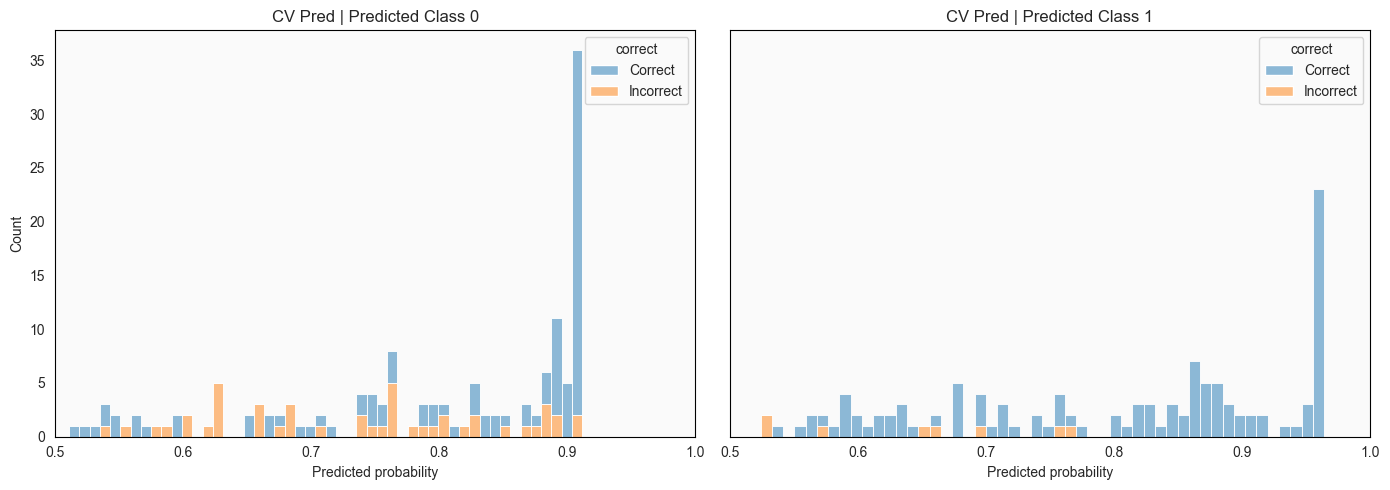

In [31]:
test_pred_probas = pd.DataFrame(
    trainer.best_pipeline.predict_proba(X_test),
    index=X_test.index
)

test_pred_lot = test_pred_probas.groupby(test_pred_probas.index).median().idxmax(axis=1)
y_test_nodup = selected_y_test_encoded[~selected_y_test_encoded.index.duplicated(keep='first')]

test_pred_lot = test_pred_lot.loc[y_test_nodup.index]

cfm = plot_confusion_matrix(
    y_true=y_test_nodup,
    y_pred=test_pred_lot,
    encoder=encoder,
    title="Confusion Matrix (Test Set)"
)
                                                           
test_pred_probas['correct'] = np.where(test_pred_probas.index.isin(test_pred_lot[y_test_nodup != test_pred_lot].index), 'Incorrect', 'Correct')
test_pred_probas['correct'] = pd.Categorical(test_pred_probas['correct'], categories=['Correct', 'Incorrect'], ordered=True)


# plot the distribution of predicted probabilities for the correct and incorrect predictions
proba_cols = [c for c in test_pred_probas.columns if c not in ["correct", "pred_class", "idxmax_proba"]]

test_pred_probas["pred_class"] = test_pred_probas[proba_cols].idxmax(axis=1)
test_pred_probas["idxmax_proba"] = test_pred_probas[proba_cols].max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, cls in zip(axes, sorted(test_pred_probas["pred_class"].unique())):
    sns.histplot(
        data=test_pred_probas.loc[test_pred_probas["pred_class"] == cls],
        x="idxmax_proba",
        hue="correct",
        bins=50,
        alpha=0.5,
        multiple="stack",
        ax=ax,
    )
    ax.set_title(f"CV Pred | Predicted Class {cls}")
    ax.set_xlabel("Predicted probability")
    ax.set_xlim(0.5, 1.0)  # appropriate for binary classification

plt.tight_layout()

In [ ]:
# if "dashboard_process" in globals() and dashboard_process is not None:
#     dashboard_process.terminate()
#     try:
#         dashboard_process.wait(timeout=5)
#     except Exception:
#         dashboard_process.kill()
# else:
#     print("No dashboard_process handle found in this kernel session.")

[(0.0, 0.5062224465110169)]

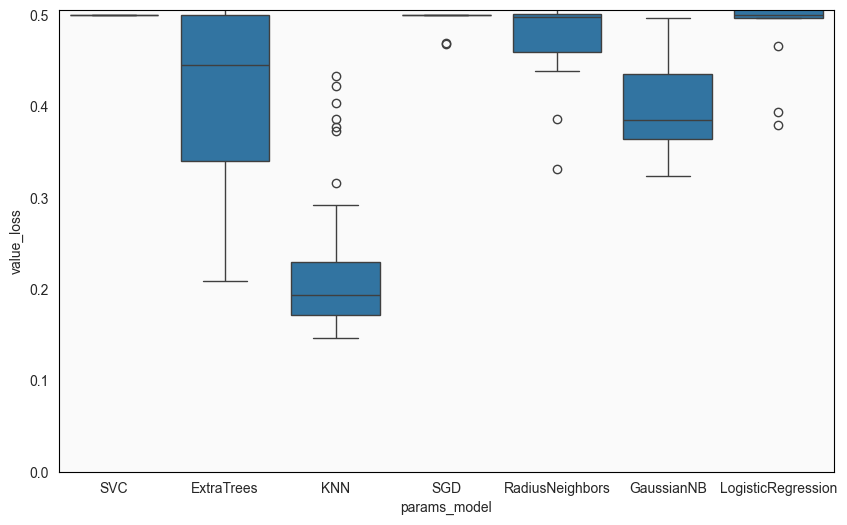

In [15]:
# plot loss ranges for each param_model
plot_df = trainer.study.trials_dataframe()

fig = plt.figure(figsize=(10, 6))

ax = sns.boxplot(x="params_model", y="value_loss", data=plot_df)

upper_threshold = plot_df["value_loss"].quantile(0.95)  # Set the threshold at the 99th percentile

# drop high outliers for better visualization
ax.set(ylim=(0, upper_threshold))

In [16]:
top_models_df = plot_df.sort_values(by="value_loss", ascending=True).drop_duplicates(subset=["params_model"], keep="first")[['number', 'value_loss', 'params_model']]
top_models_df

,number,value_loss,params_model
271,271,0.146701,KNN
61,61,0.209048,ExtraTrees
75,75,0.324060,GaussianNB
4,4,0.331663,RadiusNeighbors
24,24,0.380296,LogisticRegression
49,49,0.468464,SGD
12,12,0.500000,SVC


In [ ]:
import numpy as np

def draw_custom_cfm_on_ax(ax, **plot_kwargs):
    cfm_fig = plot_confusion_matrix(**plot_kwargs)

    # Use returned fig if your function returns one; otherwise grab current figure.
    tmp_fig = cfm_fig if hasattr(cfm_fig, "canvas") else plt.gcf()

    tmp_fig.canvas.draw()
    img = np.asarray(tmp_fig.canvas.buffer_rgba()).copy()
    plt.close(tmp_fig)

    ax.imshow(img)
    ax.axis("off")

In [ ]:
n_models = len(top_models_df)

fig, axes = plt.subplots(
    nrows=n_models,
    ncols=2,
    figsize=(14, 6 * n_models),
    squeeze=False
)

selected_y_test = y_test[[param]]
selected_y_test_encoded = pd.Series(
    encoder.transform(selected_y_test).ravel(),
    index=selected_y_test.index
)

y_train_true_encoded = selected_y_train_encoded.groupby(
    selected_y_train_encoded.index
).first()

y_test_true_encoded = selected_y_test_encoded.groupby(
    selected_y_test_encoded.index
).first()

for row_idx, number in enumerate(top_models_df["number"]):
    check_params = trainer.study.trials[number].params
    print(check_params)

    check_pipeline = construct_pipeline_from_params(
        datatype="v4",
        task_type="classify",
        params_dict=check_params
    )

    y_train_pred_encoded = cross_group_predict(
        check_pipeline,
        X_train,
        selected_y_train_encoded,
        groups=selected_y_train_encoded.index,
        cv=STRATIFIED_KFOLD
    )

    check_pipeline.fit(X_train, selected_y_train_encoded)

    y_test_pred_encoded = (
        pd.DataFrame(
            check_pipeline.predict_proba(X_test),
            index=X_test.index
        )
        .groupby(X_test.index)
        .median()
        .idxmax(axis=1)
    )

    model_steps = "-".join(check_pipeline.named_steps.keys())

    draw_custom_cfm_on_ax(
        axes[row_idx, 0],
        y_true=y_train_true_encoded.values.reshape(-1, 1),
        y_pred=y_train_pred_encoded.values.reshape(-1, 1),
        encoder=encoder,
        param=f"Trial {number}\n{model_steps}\n{param}",
        title="train"
    )

    draw_custom_cfm_on_ax(
        axes[row_idx, 1],
        y_true=y_test_true_encoded.values.reshape(-1, 1),
        y_pred=y_test_pred_encoded.values.reshape(-1, 1),
        encoder=encoder,
        param=f"Trial {number}\n{model_steps}\n{param}",
        title="test"
    )

fig.tight_layout()
plt.show()